In [1]:
!pip install -U langchain langchain-openai python-dotenv


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



  Using cached langchain-1.4.1-py3-none-any.whl.metadata (6.2 kB)
  Using cached langchain_openai-1.6.2-py3-none-any.whl.metadata (3.4 kB)
  Using cached python_dotenv-1.2.3-py3-none-any.whl.metadata (29 kB)
  Using cached langchain_core-1.6.3-py3-none-any.whl.metadata (4.8 kB)
  Using cached langgraph-1.2.11-py3-none-any.whl.metadata (4.9 kB)
  Using cached langgraph_checkpoint-4.2.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.0-py3-none-any.whl.metadata (5.2 kB)
  Using cached langgraph_sdk-0.4.4-py3-none-any.whl.metadata (5.1 kB)
Using cached langchain-1.4.1-py3-none-any.whl (161 kB)
Using cached langchain_core-1.6.3-py3-none-any.whl (571 kB)
Using cached langgraph-1.2.11-py3-none-any.whl (248 kB)
Using cached langgraph_checkpoint-4.2.0-py3-none-any.whl (56 kB)
Using cached langgraph_prebuilt-1.1.0-py3-none-any.whl (41 kB)
Using cached langgraph_sdk-0.4.4-py3-none-any.whl (162 kB)
Using cached langchain_openai-1.6.2-py3-none-any.whl (125 kB)
Using cache

In [3]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

from dotenv import load_dotenv

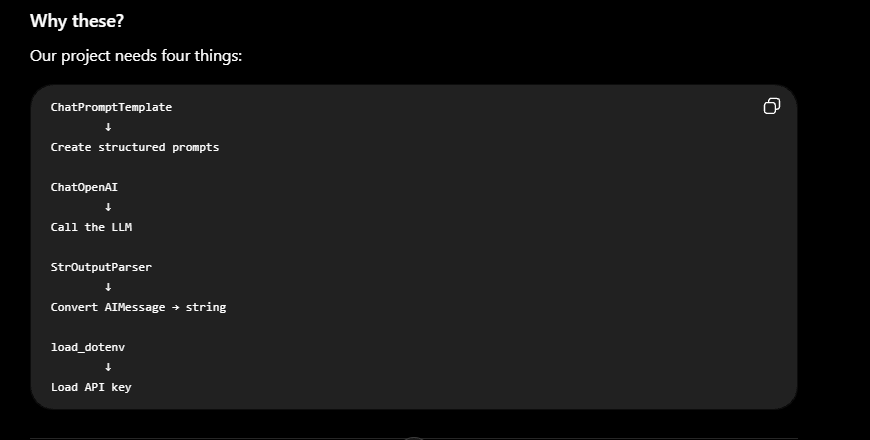

In [ ]:
load_dotenv()

True

In [5]:
# Intialize The Model
llm = ChatOpenAI(
    model = 'gpt-4o-mini',
    temperature=0
)

In [6]:
explanation_prompt = ChatPromptTemplate.from_template(
    """
    You are techinal teacher.

    Explain the following topic in details

    Topic: {topic}

    Cover:
    1. What it is
    2. Why it is needed
    3. How it works
    4. Important concepts
    5. A simple example
    """
)

In [7]:
# Create the First Chain
# Prompt → LLM → Output Parser
explanation_chain = (
    explanation_prompt | llm | StrOutputParser()
)

In [8]:
# topic
#   ↓
# explanation_prompt
#   ↓
# ChatOpenAI
#   ↓
# StrOutputParser
#   ↓
# string

In [10]:
# Test the First Chain
result = explanation_chain.invoke({
    "topic": "Retrieval Augmented Generation"
})

print(result)

### Retrieval Augmented Generation (RAG)

Retrieval Augmented Generation (RAG) is a hybrid approach that combines the strengths of information retrieval and natural language generation. It is particularly useful in scenarios where generating accurate and contextually relevant responses is crucial, such as in chatbots, question-answering systems, and content generation.

#### 1. What it is

Retrieval Augmented Generation is a framework that enhances the capabilities of generative models (like GPT-3 or BERT) by integrating them with a retrieval mechanism. The idea is to first retrieve relevant information from a large corpus of documents or data and then use that information to generate more accurate and contextually appropriate responses.

In essence, RAG consists of two main components:
- **Retrieval Component**: This part searches a database or knowledge base to find relevant documents or pieces of information based on a given query.
- **Generation Component**: This part takes the ret

In [11]:
# Create the Summary Prompt
summary_prompt = ChatPromptTemplate.from_template("""
You are an expert at creating revision notes.

Below is a detailed explanation of a technical topic:

{explanation}

Create a concise summary containing:
1. The core idea
2. 5 important points
3. One simple example
4. One common mistake beginners make

Keep the answer easy to revise.
""")

In [12]:
# Create the Summary Chain
summary_chain =  (
    summary_prompt | llm | StrOutputParser()
)

In [13]:
# Manually Test Chain 2
summary = summary_chain.invoke({
    "explanation":result
})

print(summary)

### Retrieval Augmented Generation (RAG) Summary

#### Core Idea
Retrieval Augmented Generation (RAG) is a hybrid framework that combines information retrieval and natural language generation to produce accurate and contextually relevant responses by first retrieving relevant information from a knowledge base and then generating a coherent answer.

#### Important Points
1. **Two Components**: RAG consists of a Retrieval Component (searches for relevant documents) and a Generation Component (creates responses based on retrieved information).
2. **Access to External Knowledge**: RAG enhances generative models by allowing them to pull in up-to-date information from external sources.
3. **Contextual Relevance**: By grounding responses in real-world data, RAG improves the accuracy and relevance of generated answers.
4. **Mitigating Hallucinations**: RAG reduces the occurrence of false information ("hallucinations") by basing responses on retrieved data.
5. **End-to-End Training**: Some RAG 

In [14]:
# Create the Complete Chain
full_chain = explanation_chain | (
    lambda explanation: summary_chain.invoke({
        "explanation": explanation
    })
)

In [15]:
final_result = full_chain.invoke({
    "topic": "Retrieval Augmented Generation"
})

print(final_result)

### Summary of Retrieval Augmented Generation (RAG)

#### Core Idea
Retrieval Augmented Generation (RAG) is a hybrid NLP approach that combines information retrieval and generative models to produce accurate and contextually relevant text by grounding outputs in real-world data.

#### Important Points
1. **Hybrid Model**: RAG integrates a retrieval system to fetch relevant documents and a generative model to create coherent text based on that information.
2. **Addressing Limitations**: RAG overcomes knowledge limitations, contextual relevance issues, and scalability challenges faced by traditional generative models.
3. **Process Steps**: The RAG process includes query formation, information retrieval, contextualization, text generation, and output presentation.
4. **Retrieval and Generative Models**: Retrieval models (e.g., BM25) fetch documents, while generative models (e.g., GPT-3) produce text based on the retrieved context.
5. **Fine-tuning**: RAG models can be fine-tuned for speci

In [16]:
# Use RunnableLambda
from langchain_core.runnables import RunnableLambda

In [17]:
summary_step = RunnableLambda(
    lambda explanation: summary_chain.invoke({
        "explanation": explanation
    })
)

In [18]:
full_chain = explanation_chain | summary_step

In [19]:
final_result = full_chain.invoke({
    "topic": "Retrieval Augmented Generation"
})

print(final_result)

### Summary of Retrieval Augmented Generation (RAG)

#### Core Idea
Retrieval Augmented Generation (RAG) is a hybrid NLP approach that combines information retrieval and generative models to produce accurate and contextually relevant text by grounding outputs in real-world data.

#### 5 Important Points
1. **Hybrid Model**: RAG integrates a retrieval system to fetch relevant documents and a generative model to create coherent text based on that information.
2. **Addressing Limitations**: It overcomes the knowledge limitations of traditional generative models by accessing up-to-date information dynamically.
3. **Two Phases**: The process consists of a retrieval phase (fetching relevant documents) and a generation phase (producing text using the retrieved information).
4. **Contextualization**: Retrieved information is used to inform the generative model, ensuring responses are relevant to user queries.
5. **Evaluation Metrics**: Performance is assessed using metrics like accuracy, relev